In [6]:
"""
Pipeline EEG (dataset Bonn) :
  1. Notch 50 Hz
  2. Passe-bande Butterworth 0,5 - 80 Hz
  3. Filtre anti-impulsionnel multi-échelles (médiane + MAD locale,
     correction par interpolation linéaire)

Sauvegarde : DOSSIER_SORTIE/<classe>/segment_XXXX.npy (reprise possible)
"""
from pathlib import Path

import numpy as np
from scipy.ndimage import median_filter
from scipy.signal import butter, iirnotch, sosfiltfilt, filtfilt
from tqdm.auto import tqdm

# ============================================================
# Paramètres
# ============================================================
DOSSIER_BRUT = Path("Epilepsy-EEG")            # contient A, B, C, D, E
DOSSIER_SORTIE = Path("pipeline_notch50_bp0.5_80_impulse2.5")
CLASSES = ["A", "B", "C", "D", "E"]

FS = 173.61            # Hz (Bonn)

NOTCH_F0 = 50.0        # Hz
NOTCH_Q = 30           # plus grand = notch plus étroit
NOTCH_FORCE = 0.85      # 1 = notch complet ; 0.85 = mélange comme avant

BP_BAND = (0.5, 80.0)  # Hz
BP_ORDER = 4

IMP_SCALES_MS = (30, 65, 120, 230)  # échelles temporelles de détection
IMP_NOISE_WINDOW_S = 1.0            # fenêtre de la MAD locale
IMP_THRESHOLD = 2.5                 # seuil en sigmas locaux
IMP_PADDING = 1                     # échantillons ajoutés autour des détections


# ============================================================
# 1. Notch 50 Hz
# ============================================================
def notch(x, fs=FS, f0=NOTCH_F0, Q=NOTCH_Q, force=NOTCH_FORCE):
    b, a = iirnotch(w0=f0, Q=Q, fs=fs)
    filtre = filtfilt(b, a, x, axis=-1)
    return (1 - force) * x + force * filtre


# ============================================================
# 2. Passe-bande 0,5 - 80 Hz
# ============================================================
SOS_BP = butter(BP_ORDER, BP_BAND, btype="bandpass", fs=FS, output="sos")


def passe_bande(x):
    return sosfiltfilt(SOS_BP, x, axis=-1)


# ============================================================
# 3. Anti-impulsionnel : médiane + MAD locale multi-échelles
# ============================================================
def detect_impulses(
    x,
    fs=FS,
    scales_ms=IMP_SCALES_MS,
    noise_window_s=IMP_NOISE_WINDOW_S,
    threshold=IMP_THRESHOLD,
):
    """Masque booléen des impulsions (positives et négatives)."""
    x = np.asarray(x, dtype=float).squeeze()

    if x.ndim != 1:
        raise ValueError("Chaque segment EEG doit être 1D.")
    if len(x) < 5:
        return np.zeros(len(x), dtype=bool)
    if not np.all(np.isfinite(x)):
        raise ValueError("Le signal contient des NaN ou des infinis.")

    noise_window = max(5, int(round(noise_window_s * fs)))
    if noise_window % 2 == 0:
        noise_window += 1

    global_sigma = 1.4826 * np.median(np.abs(x - np.median(x)))
    floor = max(global_sigma * 1e-3, np.finfo(float).eps)

    detections = np.zeros(len(x), dtype=int)

    for scale_ms in scales_ms:
        width = max(3, int(round(scale_ms * fs / 1000)))
        if width % 2 == 0:
            width += 1

        baseline = median_filter(x, size=width, mode="reflect")
        residual = x - baseline

        center = median_filter(residual, size=noise_window, mode="reflect")
        dev = np.abs(residual - center)
        local_sigma = 1.4826 * median_filter(
            dev, size=noise_window, mode="reflect"
        )
        local_sigma = np.maximum(local_sigma, floor)

        detections += dev > threshold * local_sigma

    return detections > 0


def correct_impulses(x, mask, padding=IMP_PADDING):
    """Interpolation linéaire des points détectés (masque élargi de `padding`)."""
    x = np.asarray(x, dtype=float).squeeze()
    mask = np.asarray(mask, dtype=bool).copy()

    if padding > 0 and np.any(mask):
        original = mask.copy()
        for shift in range(1, padding + 1):
            mask[shift:] |= original[:-shift]
            mask[:-shift] |= original[shift:]

    corrige = x.copy()
    valid = ~mask
    if np.any(mask) and np.any(valid):
        idx = np.arange(len(x))
        corrige[mask] = np.interp(idx[mask], idx[valid], x[valid])

    return corrige, mask


# ============================================================
# Pipeline complet sur un signal
# ============================================================
def pipeline(x):
    x = notch(x)
    x = passe_bande(x)
    masque = detect_impulses(x)
    x, masque = correct_impulses(x, masque)
    return x, masque


# ============================================================
# Application à tout le dataset, avec sauvegarde et reprise
# ============================================================
def charger_brut():
    """{classe: array (100, 4097)} depuis les .txt."""
    data = {}
    for c in CLASSES:
        fichiers = sorted(
            f for f in (DOSSIER_BRUT / c).iterdir()
            if f.is_file() and f.suffix.lower() == ".txt"
        )
        data[c] = np.array([np.loadtxt(f) for f in fichiers])
    return data

import re
import numpy as np
from pathlib import Path

DOSSIER_BRUT = Path("Epilepsy-EEG")
CLASSES = ["A", "B", "C", "D", "E"]
FICHIER_SPLIT = Path("subdatat.txt")


def lire_split(fichier=FICHIER_SPLIT):
    """Parse la sortie 'tree /f' (encodage mixte) -> {'train': {classe: [indices]}, 'test': {...}}."""
    brut = fichier.read_bytes().replace(b"\x00", b"")
    texte = brut.decode("latin-1")

    split = {"train": {c: [] for c in CLASSES}, "test": {c: [] for c in CLASSES}}
    ens, classe = None, None

    for ligne in texte.splitlines():
        m = re.search(r"segment_(\d+)\.npy", ligne)
        if m:
            if ens and classe:
                split[ens][classe].append(int(m.group(1)))
            continue

        # ligne de dossier : préfixe d'arbre (non alphanumérique) + nom
        m = re.search(r"(?:^|\W)(entrainement|test|[A-E])\s*$", ligne)
        if m:
            nom = m.group(1)
            if nom == "entrainement":
                ens, classe = "train", None
            elif nom == "test":
                ens, classe = "test", None
            else:
                classe = nom

    # Vérification : train et test disjoints, 100 indices par classe
    for c in CLASSES:
        tr, te = set(split["train"][c]), set(split["test"][c])
        assert not (tr & te), f"Fuite train/test dans la classe {c}"
        assert tr | te == set(range(100)), f"Indices manquants dans la classe {c}"
    return split


def charger_brut_split():
    """Retourne (data_train, data_test), chacun au format de charger_brut :
    {classe: array (n_classe, 4097)}."""
    split = lire_split()   # même fonction que précédemment

    data_train, data_test = {}, {}
    for c in CLASSES:
        fichiers = sorted(
            f for f in (DOSSIER_BRUT / c).iterdir()
            if f.is_file() and f.suffix.lower() == ".txt"
        )
        data_train[c] = np.array([np.loadtxt(fichiers[i]) for i in sorted(split["train"][c])])
        data_test[c]  = np.array([np.loadtxt(fichiers[i]) for i in sorted(split["test"][c])])
    return data_train, data_test


data_train, data_test = charger_brut_split()



def sauver_atomique(chemin: Path, arr):
    tmp = chemin.with_name(chemin.name + ".tmp.npy")
    np.save(tmp, arr)
    tmp.replace(chemin)

DOSSIERS_ENS = {"train": "entrainement", "test": "test"}

def traiter_dataset(data, ensemble, split):
    """
    data     : {classe: array}  (data_train ou data_test)
    ensemble : "train" ou "test"
    split    : sortie de lire_split()
    Retourne data_final et masques (dicts par classe).
    """
    data_final, masques = {}, {}
    total = sum(v.shape[0] for v in data.values())

    with tqdm(total=total, desc=f"Pipeline EEG [{ensemble}]", unit="segment") as barre:
        for classe, signaux in data.items():
            indices = sorted(split[ensemble][classe])      # indices d'origine, même ordre que signaux
            assert len(indices) == len(signaux), f"{ensemble}/{classe} : incohérence"

            dossier = DOSSIER_SORTIE / DOSSIERS_ENS[ensemble] / classe
            dossier.mkdir(parents=True, exist_ok=True)

            sortie = np.empty_like(signaux, dtype=np.float64)
            m = np.zeros(signaux.shape, dtype=bool)

            for k, (idx, x) in enumerate(zip(indices, signaux)):
                chemin = dossier / f"segment_{idx:04d}.npy"
                chemin_masque = dossier / f"masque_{idx:04d}.npy"

                if chemin.exists() and chemin_masque.exists():
                    try:
                        sortie[k] = np.load(chemin, allow_pickle=False)
                        m[k] = np.load(chemin_masque, allow_pickle=False)
                        barre.update(1)
                        continue
                    except (OSError, ValueError):
                        pass  # fichier invalide : on recalcule

                sortie[k], m[k] = pipeline(x)
                sauver_atomique(chemin, sortie[k])
                sauver_atomique(chemin_masque, m[k])
                barre.update(1)

            data_final[classe] = sortie
            masques[classe] = m
            print(f"[{ensemble}] Classe {classe} : {sortie.shape}, "
                  f"{100 * m.mean():.3f} % de points corrigés")

    return data_final, masques


split = lire_split()
data_train, data_test = charger_brut_split()
final_train, masques_train = traiter_dataset(data_train, "train", split)
final_test,  masques_test  = traiter_dataset(data_test,  "test",  split)
def traiter_splits(train=None, test=None, split=None, verifier=True):
    """
    train, test : data_train / data_test issus de charger_brut_split() (l'un, l'autre ou les deux).
    Traite chaque ensemble fourni, met à jour DOSSIER_SORTIE/{entrainement,test}/classe/,
    puis vérifie la structure par rapport à subdatat.txt.

    Retourne {"train": (data_final, masques), "test": (data_final, masques)}
    avec seulement les ensembles fournis.
    """
    if train is None and test is None:
        raise ValueError("Fournir au moins train ou test.")

    split = split or lire_split()
    entrees = {"train": train, "test": test}
    resultats = {}

    for ens, data in entrees.items():
        if data is None:
            continue
        resultats[ens] = traiter_dataset(data, ens, split)


    return resultats


if __name__ == "__main__":
    data_train, data_test = charger_brut_split()
    data_train, data_test = charger_brut_split()
    
    res = traiter_splits(train=data_train, test=data_test)
    final_train, masques_train = res["train"]
    final_test,  masques_test  = res["test"]

    print("Résultats dans :", DOSSIER_SORTIE.resolve())

Pipeline EEG [train]:   0%|          | 0/460 [00:00<?, ?segment/s]

[train] Classe A : (95, 4097), 78.618 % de points corrigés
[train] Classe B : (95, 4097), 71.865 % de points corrigés
[train] Classe C : (95, 4097), 76.220 % de points corrigés
[train] Classe D : (95, 4097), 74.200 % de points corrigés
[train] Classe E : (80, 4097), 68.600 % de points corrigés


Pipeline EEG [test]:   0%|          | 0/40 [00:00<?, ?segment/s]

[test] Classe A : (5, 4097), 79.458 % de points corrigés
[test] Classe B : (5, 4097), 74.147 % de points corrigés
[test] Classe C : (5, 4097), 72.990 % de points corrigés
[test] Classe D : (5, 4097), 73.429 % de points corrigés
[test] Classe E : (20, 4097), 69.332 % de points corrigés


Pipeline EEG [train]:   0%|          | 0/460 [00:00<?, ?segment/s]

[train] Classe A : (95, 4097), 78.618 % de points corrigés
[train] Classe B : (95, 4097), 71.865 % de points corrigés
[train] Classe C : (95, 4097), 76.220 % de points corrigés
[train] Classe D : (95, 4097), 74.200 % de points corrigés
[train] Classe E : (80, 4097), 68.600 % de points corrigés


Pipeline EEG [test]:   0%|          | 0/40 [00:00<?, ?segment/s]

[test] Classe A : (5, 4097), 79.458 % de points corrigés
[test] Classe B : (5, 4097), 74.147 % de points corrigés
[test] Classe C : (5, 4097), 72.990 % de points corrigés
[test] Classe D : (5, 4097), 73.429 % de points corrigés
[test] Classe E : (20, 4097), 69.332 % de points corrigés
Résultats dans : /mnt/adisk/yassineferhi/traitement_signal/pipeline_notch50_bp0.5_80_impulse2.5


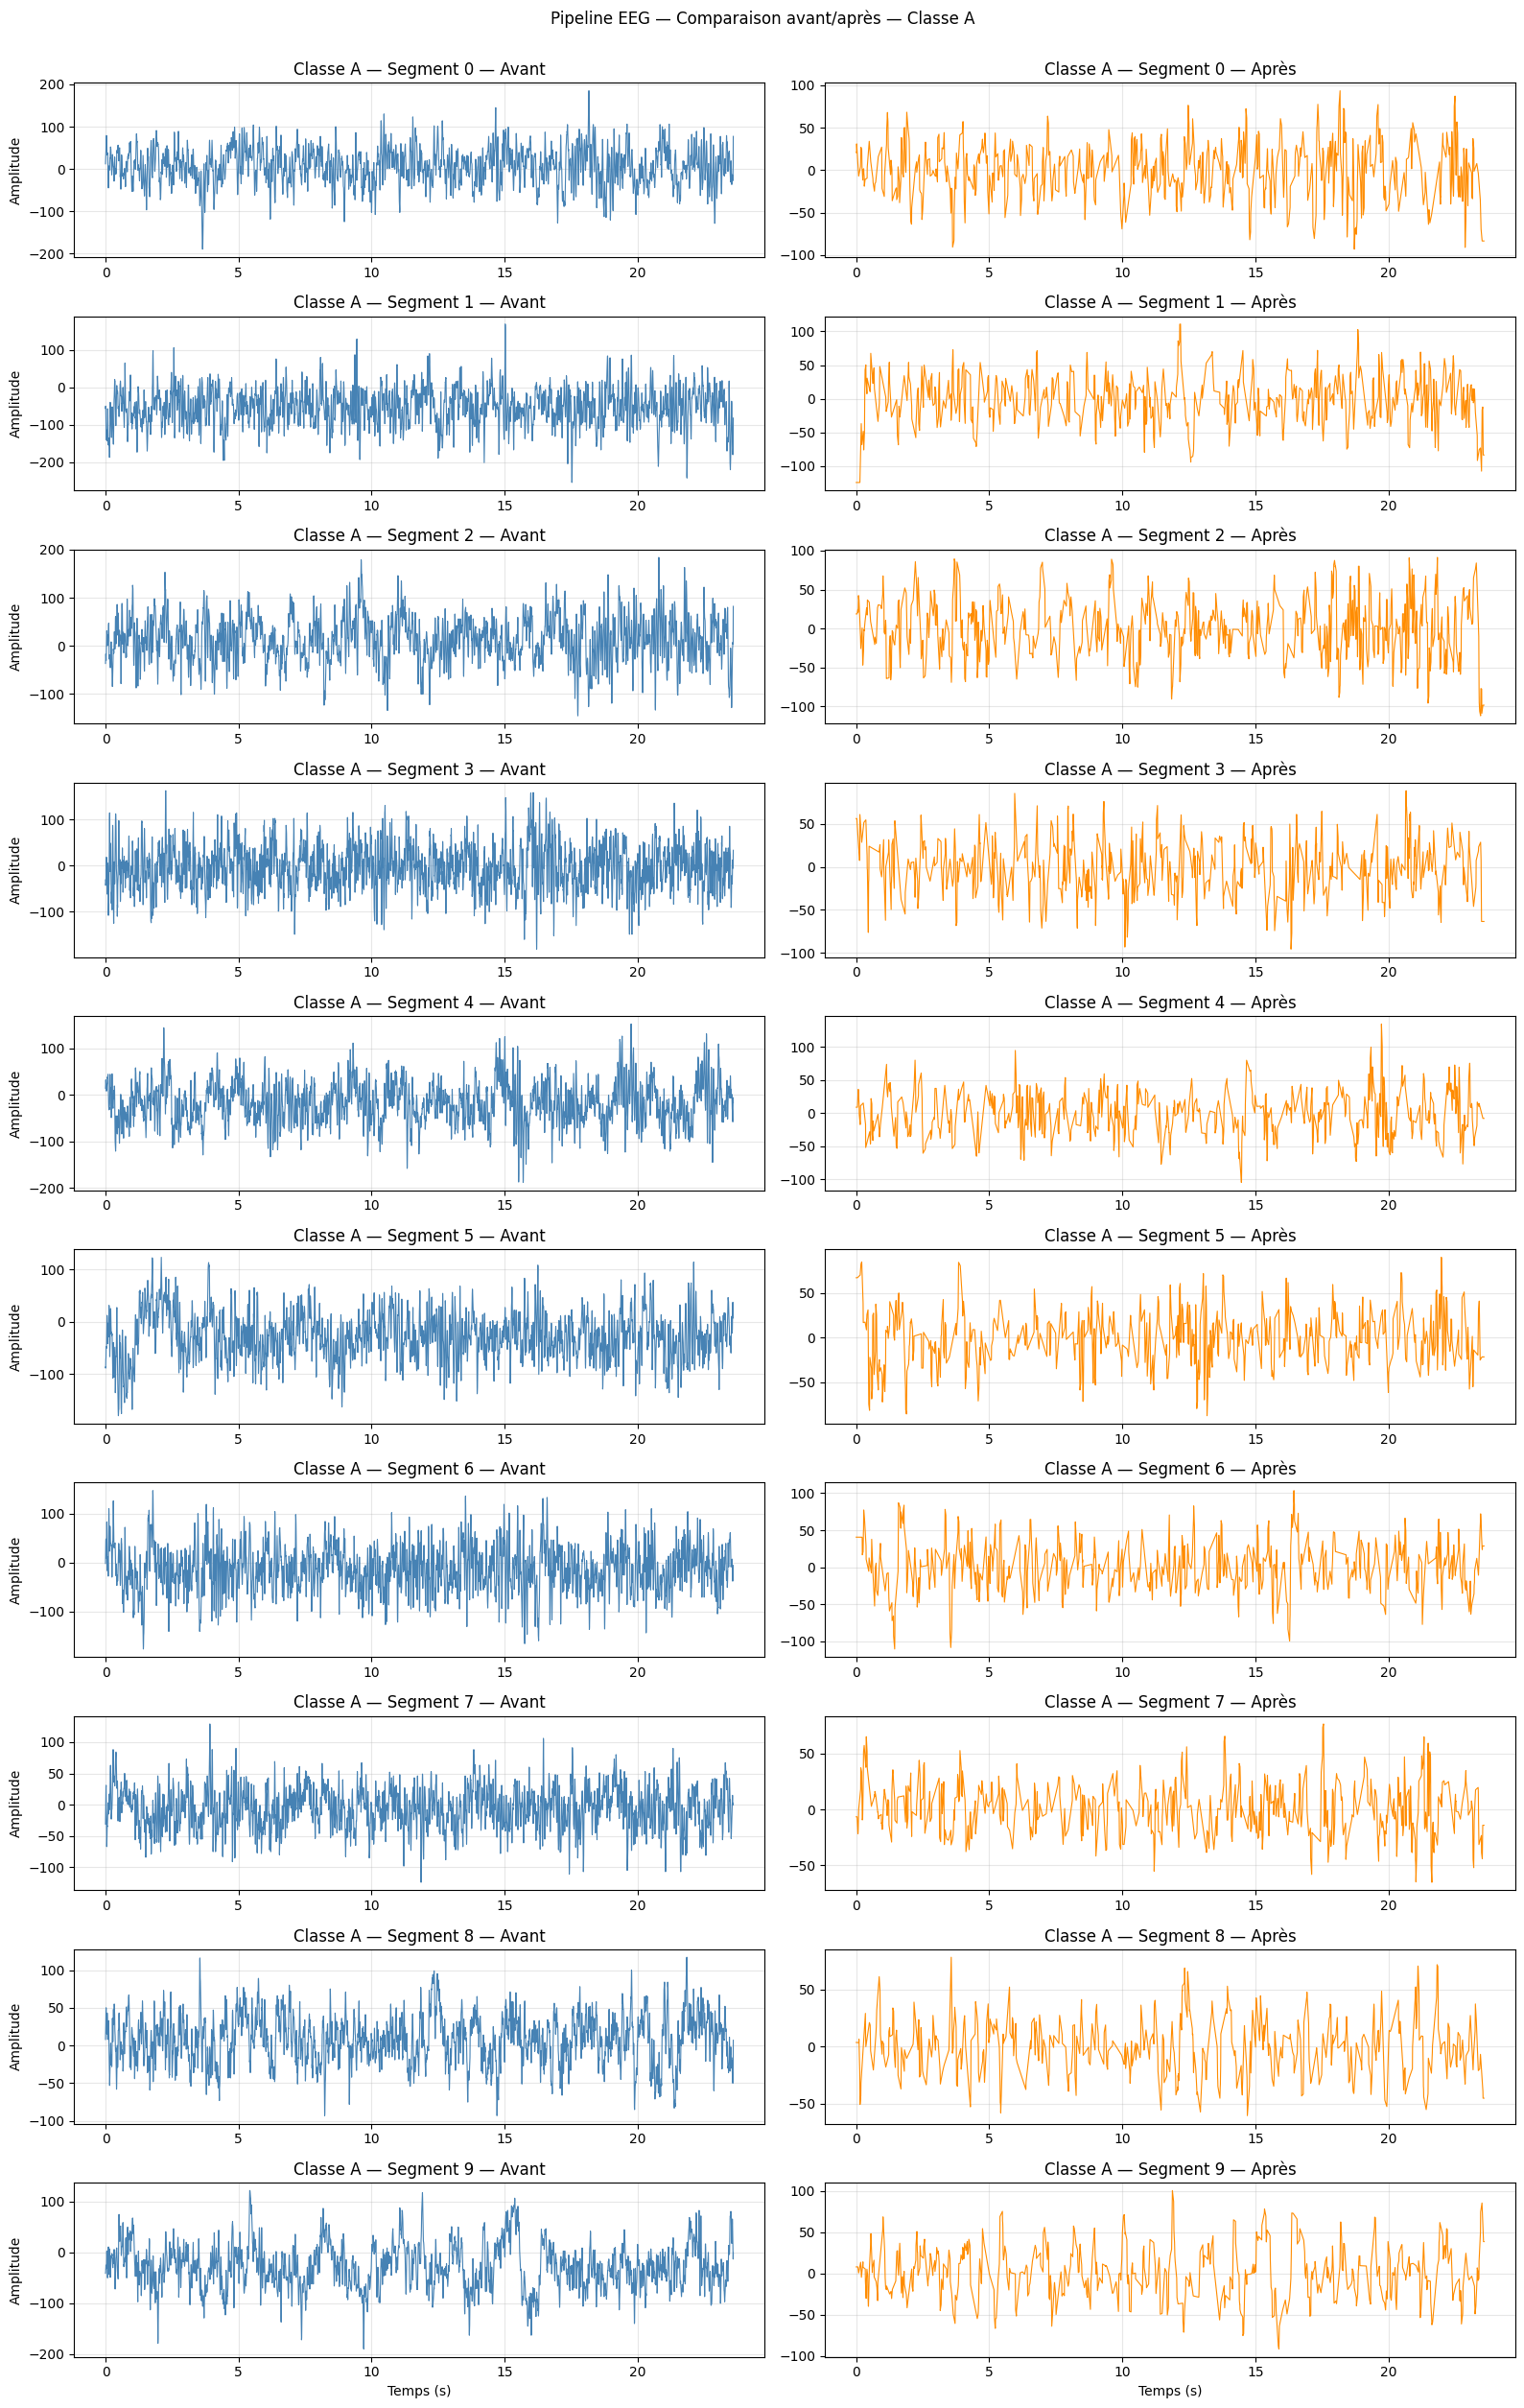

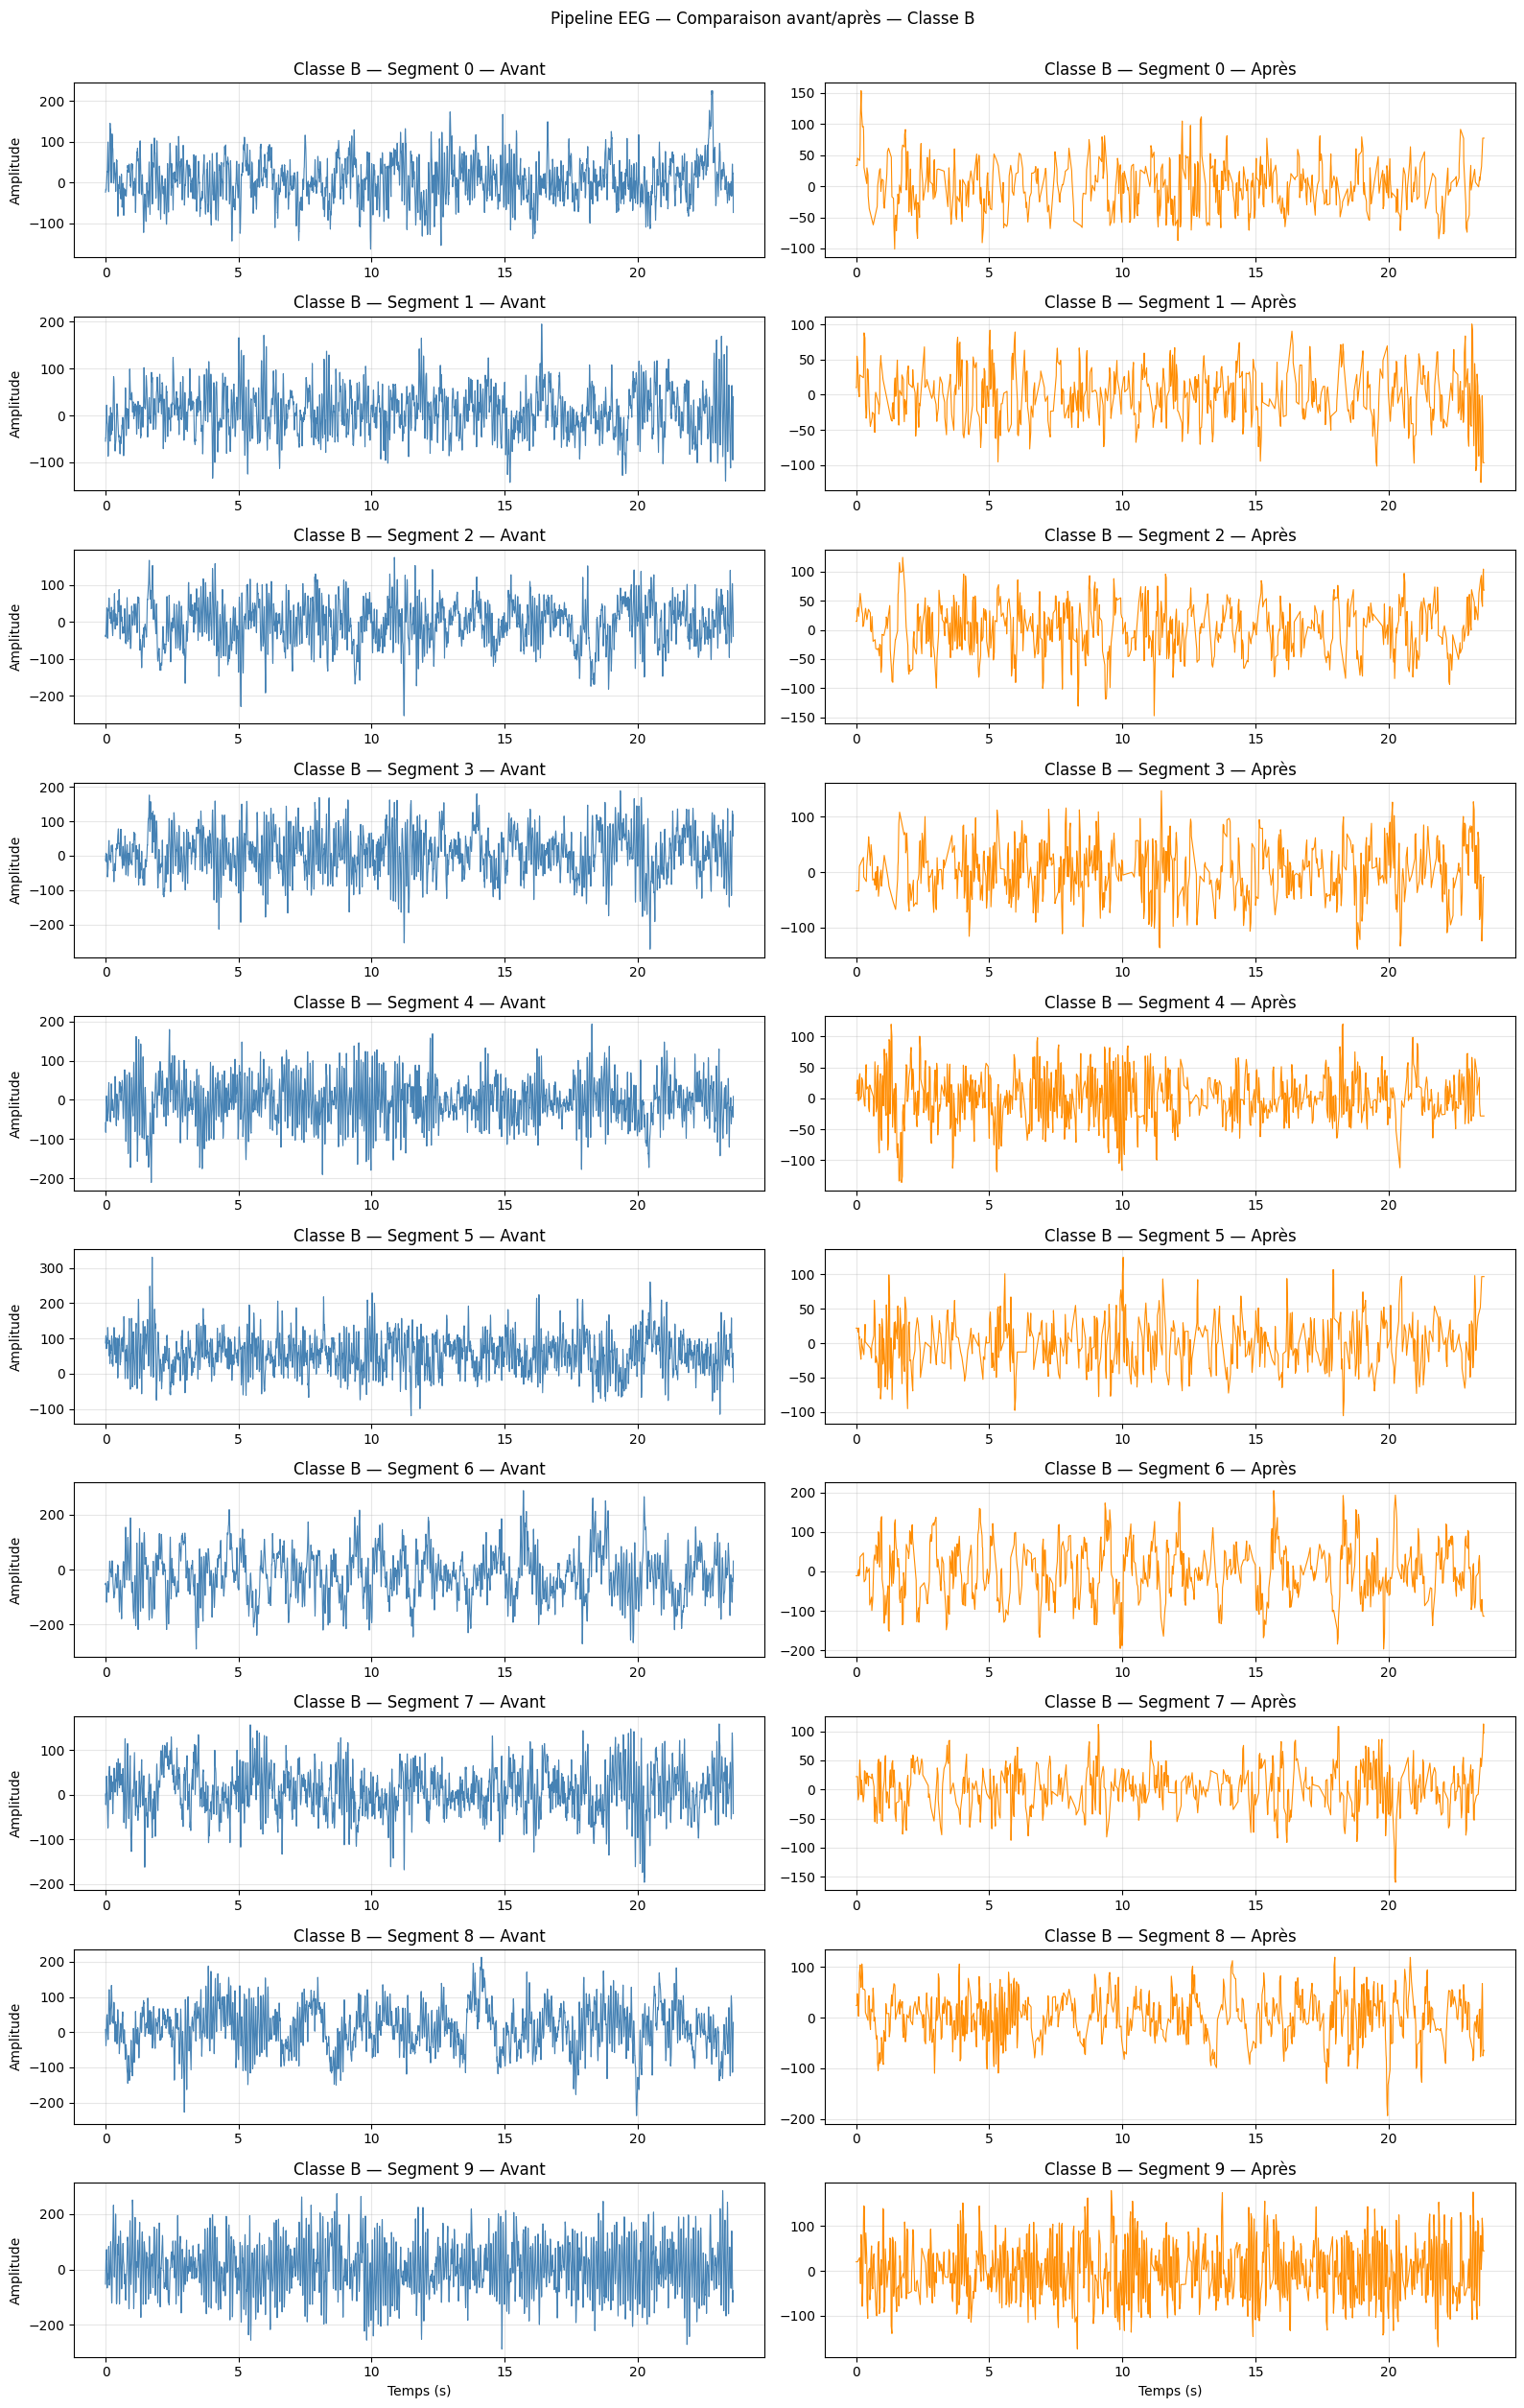

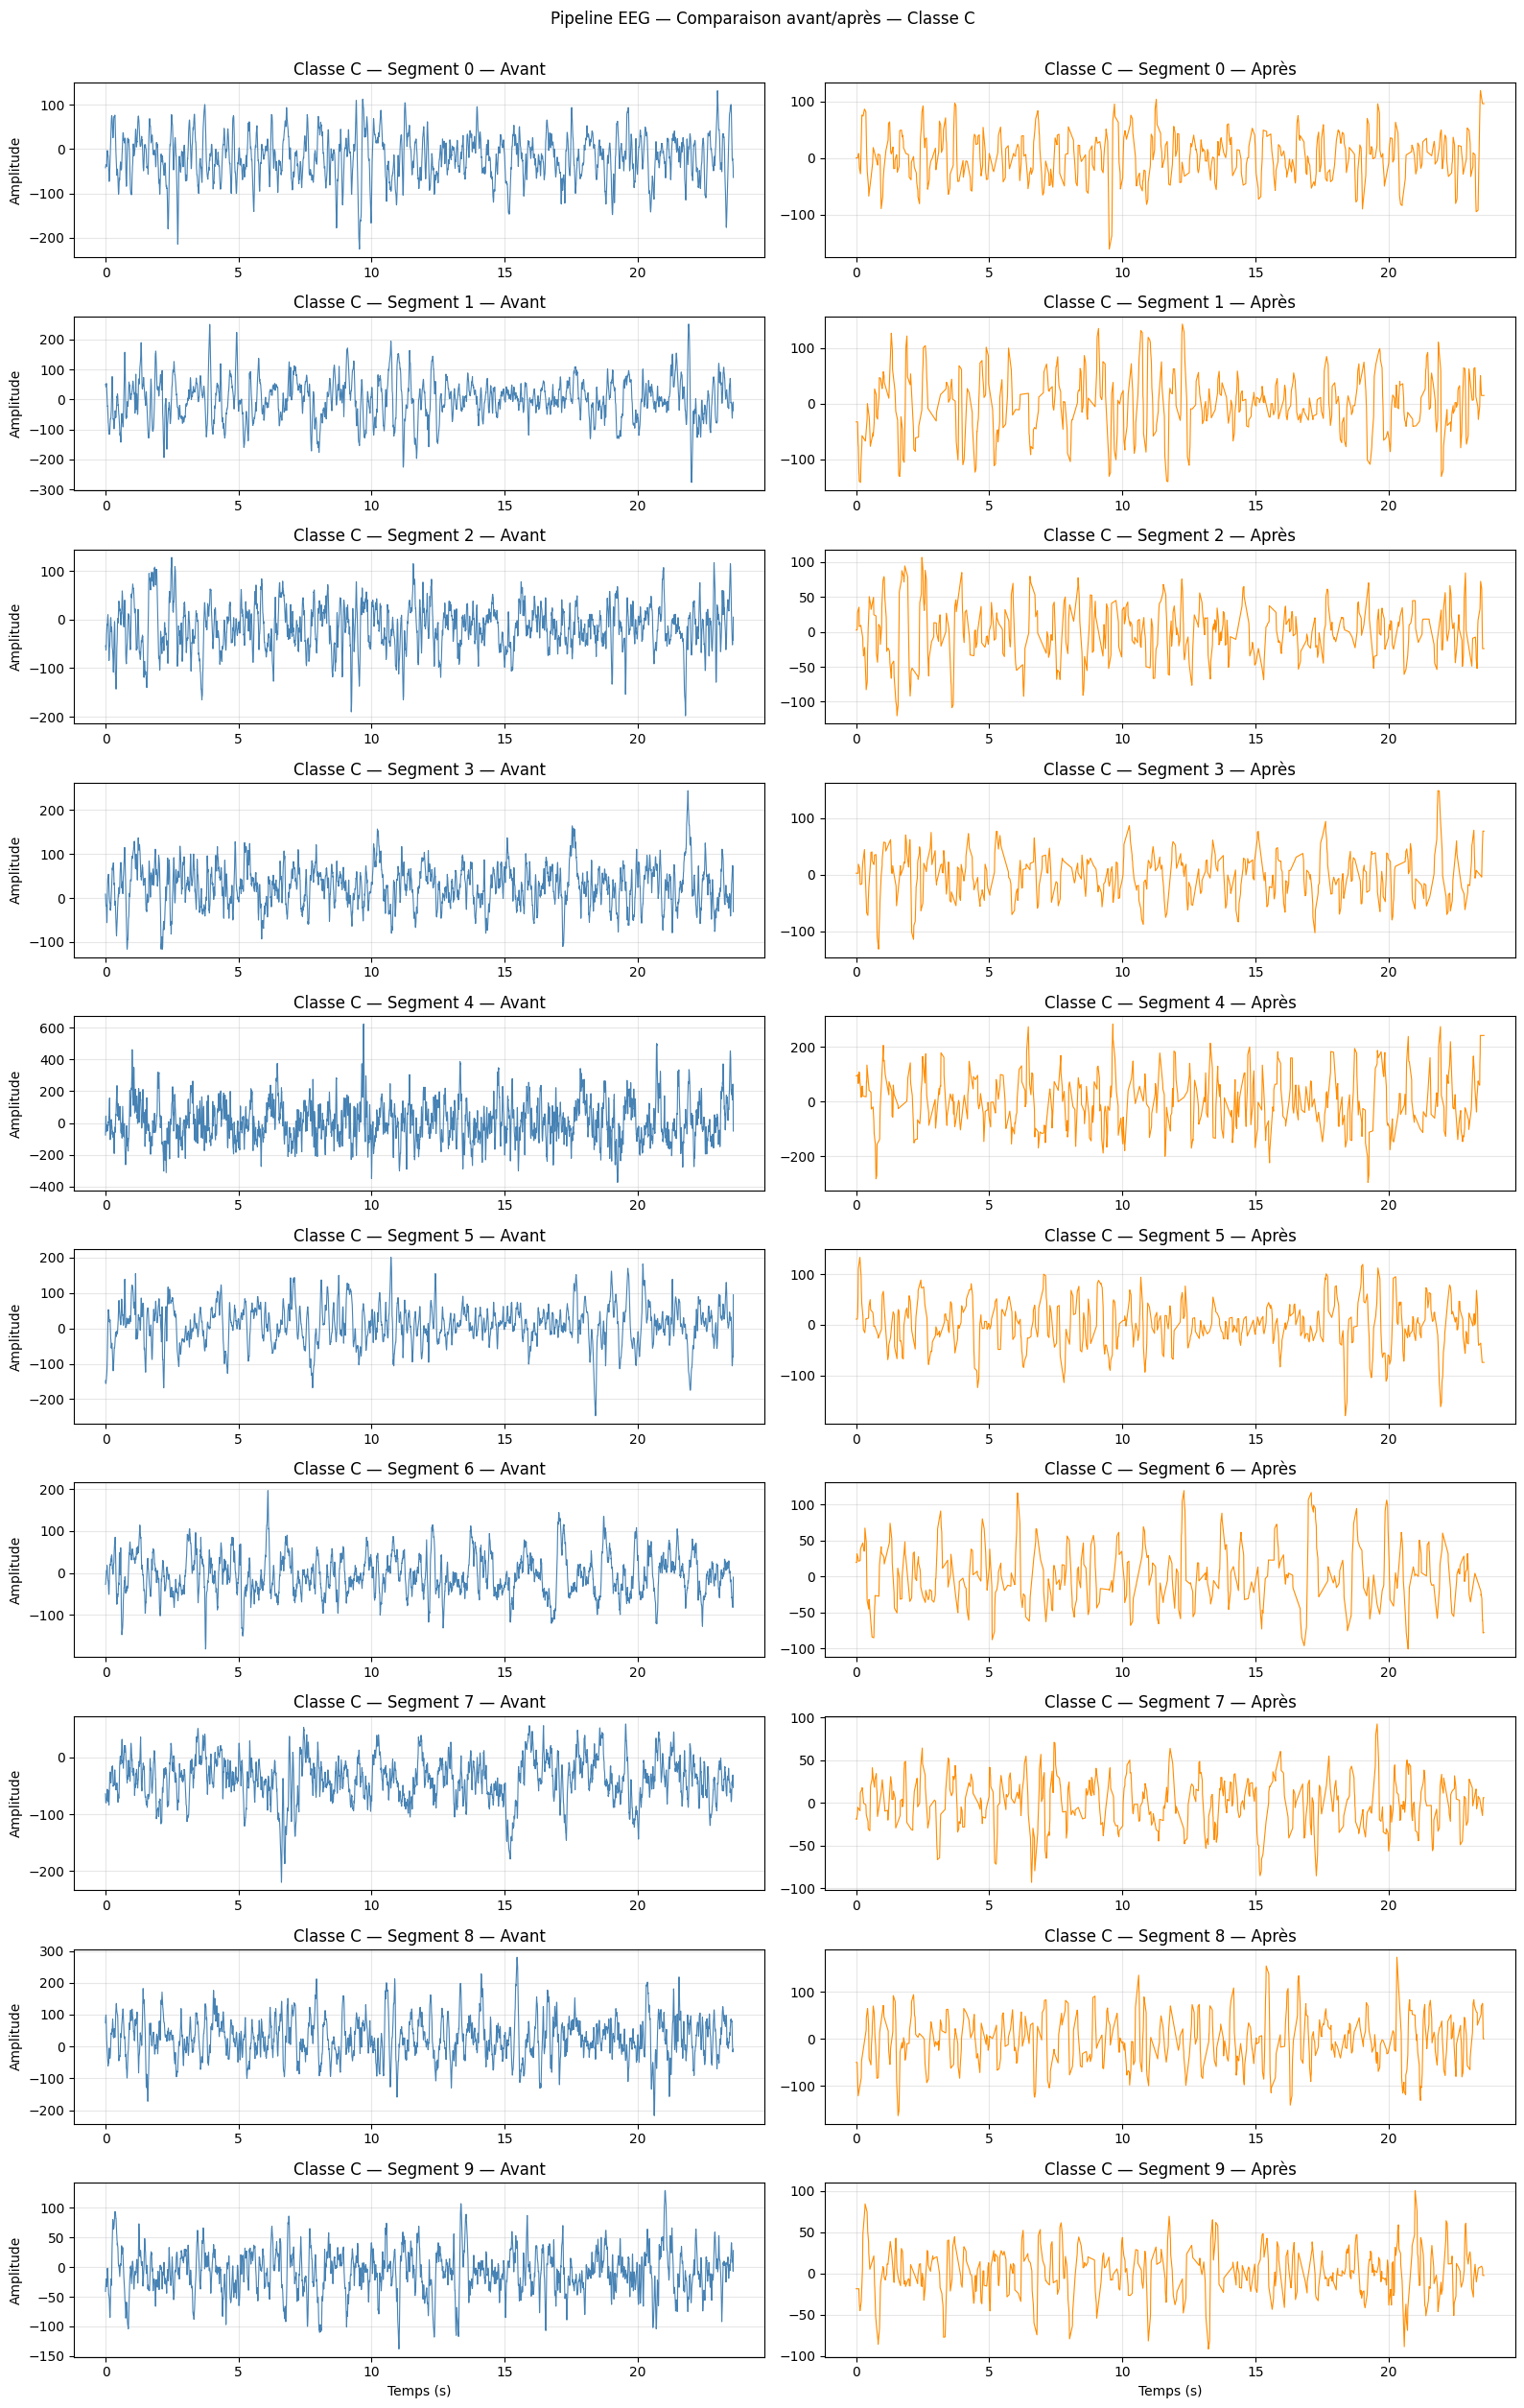

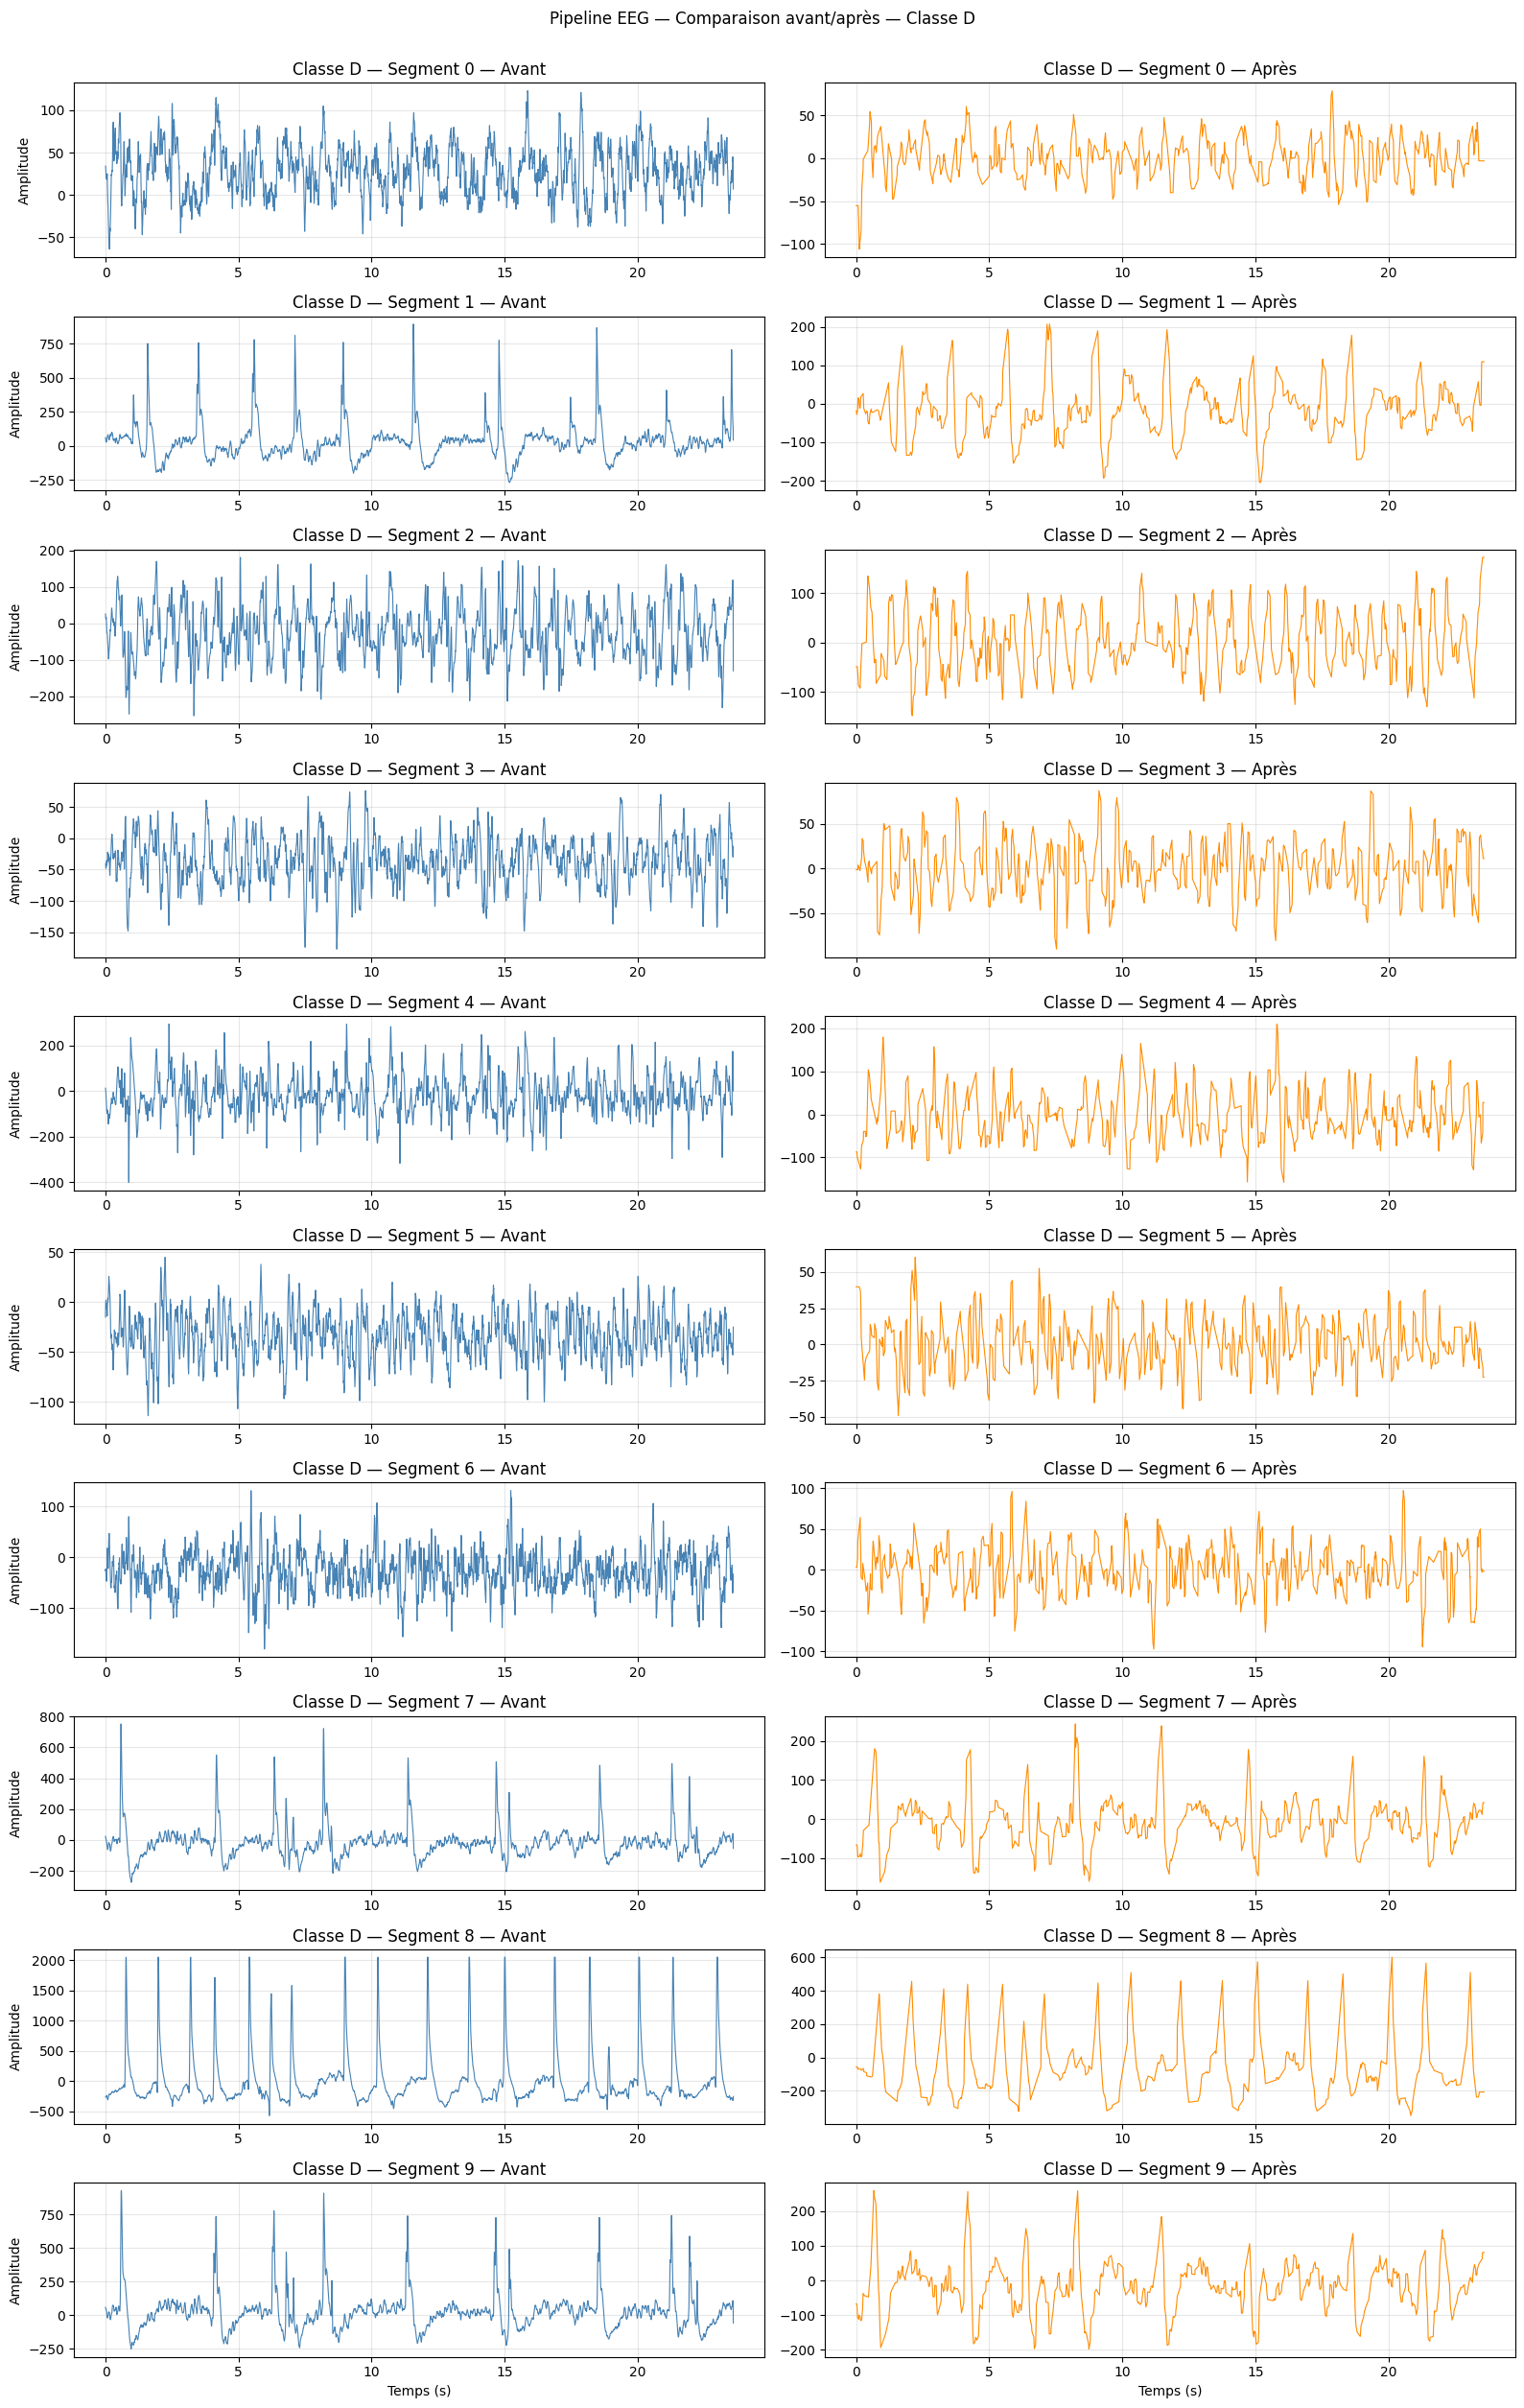

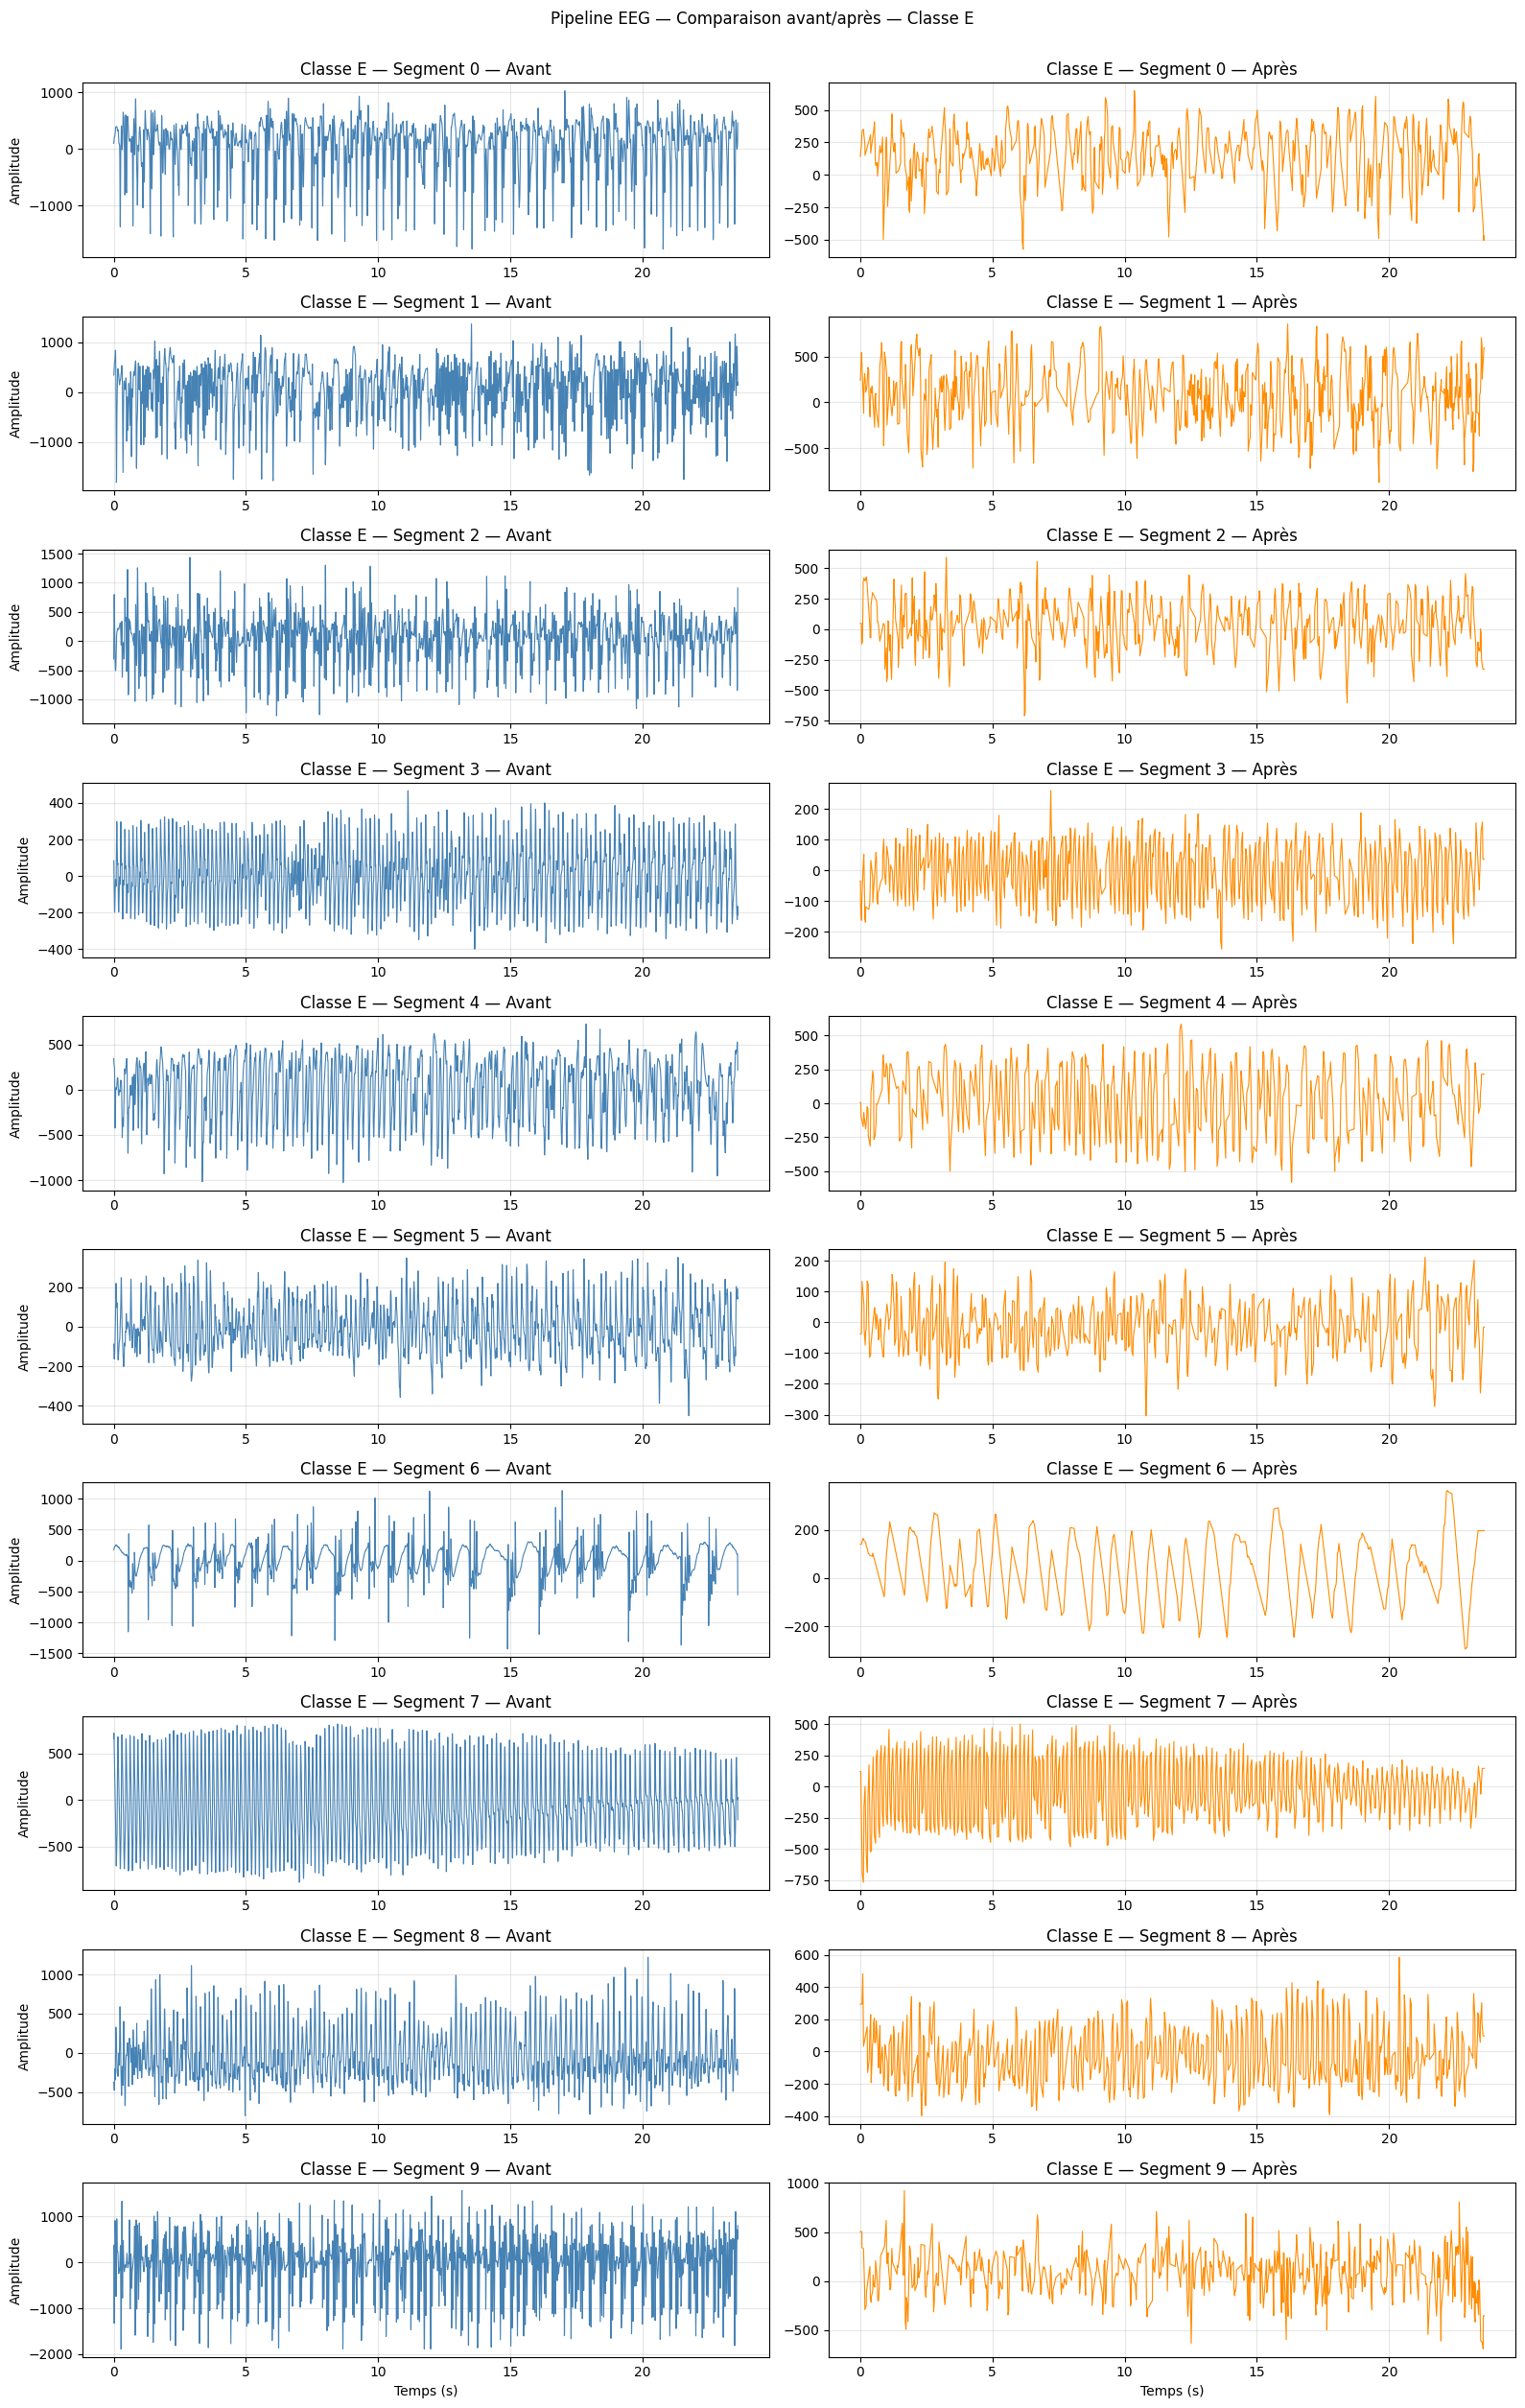

In [14]:
AFFICHER_POINTS_ROUGES = False  # True = afficher ; False = masquer
# ============================================================
# Visualisation avant / après traitement
# 10 premiers segments de chaque classe
# ============================================================

import matplotlib.pyplot as plt
import numpy as np

TEMPS_FS = FS
N_SEGMENTS = 10

for classe in CLASSES:

    signaux_bruts = data[classe]
    signaux_traites = data_final[classe]
    masques_classe = masques[classe]

    n = min(N_SEGMENTS, len(signaux_bruts))

    if n == 0:
        continue

    fig, axes = plt.subplots(
        n, 2,
        figsize=(16, 2.5 * n),
        squeeze=False
    )

    for i in range(n):

        original = np.asarray(
            signaux_bruts[i], dtype=float
        ).squeeze()

        traite = np.asarray(
            signaux_traites[i], dtype=float
        ).squeeze()

        masque = np.asarray(
            masques_classe[i], dtype=bool
        ).squeeze()

        temps = np.arange(len(original)) / TEMPS_FS

        # Avant traitement
        ax = axes[i, 0]
        ax.plot(
            temps, original,
            color="steelblue",
            linewidth=0.8
        )

        if AFFICHER_POINTS_ROUGES and masque.any():
            ax.scatter(
                temps[masque],
                original[masque],
                color="red",
                s=10,
                label="Points corrigés",
                zorder=3
            )
            ax.legend(loc="upper right", fontsize=8)

        ax.set_title(f"Classe {classe} — Segment {i} — Avant")
        ax.set_ylabel("Amplitude")
        ax.grid(True, alpha=0.3)

        # Après traitement
        ax = axes[i, 1]
        ax.plot(
            temps, traite,
            color="darkorange",
            linewidth=0.8
        )

        ax.set_title(f"Classe {classe} — Segment {i} — Après")
        ax.grid(True, alpha=0.3)

    axes[-1, 0].set_xlabel("Temps (s)")
    axes[-1, 1].set_xlabel("Temps (s)")

    fig.suptitle(
        f"Pipeline EEG — Comparaison avant/après — Classe {classe}",
        y=1.002
    )

    fig.tight_layout()
    plt.show()
